# EDA: Hotel Booking Demand (chỉ trên tập train)

Notebook này **chỉ đọc tập train** (booking đến 07/2015–12/2016). Validation và test không được mở ở đây, để mọi
quyết định tiền xử lý không bị ảnh hưởng bởi dữ liệu dùng để chọn/kết luận.

Mỗi phần kết thúc bằng một **quyết định** được ghi trong `docs/decisions.md` (mã D-xx). Hình được lưu vào
`reports/figures/eda_*.png` để dùng trong báo cáo.

Chạy lại: `make data` rồi `jupyter nbconvert --to notebook --execute --inplace notebooks/eda.ipynb`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from src.data import ROOT, load_config, load_splits

train = load_splits(load_config())["train"]   # CHỈ dùng train
FIG = ROOT / "reports" / "figures"
print(f"Train: {len(train):,} booking, ngày đến {train.arrival_date.min():%Y-%m-%d} → {train.arrival_date.max():%Y-%m-%d}")

# Cùng bảng màu với src/evaluate.py
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": AXIS,
    "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "text.color": INK, "legend.frameon": False,
    "font.size": 9.5, "figure.dpi": 100,
})
y = train["is_canceled"]
overall = y.mean()

def rate_by(col):
    return y.groupby(train[col], observed=True).agg(ty_le_huy="mean", n="size").sort_values("ty_le_huy", ascending=False)

Train: 78,586 booking, ngày đến 2015-07-01 → 2016-12-31


## 1. Biến mục tiêu

In [2]:
pd.DataFrame({"n": train.groupby("hotel").size(), "ty_le_huy": y.groupby(train.hotel).mean()}).assign(
    toan_bo=lambda d: d.index.map(lambda _: overall)).round(3)

,n,ty_le_huy,toan_bo
hotel,,,
City Hotel,51713,0.414,0.362
Resort Hotel,26873,0.263,0.362


Khoảng 36% booking trên train bị hủy; City Hotel hủy nhiều hơn Resort Hotel rõ rệt.
**Quyết định:** giữ `hotel` làm đặc trưng (D-02); vì lớp hủy chiếm hơn 1/3, dùng PR-AUC và log loss bên cạnh
ROC-AUC, thử `class_weight` cả `None` và `balanced` (D-13).

## 2. Lead time: lệch phải, quan hệ phi tuyến với tỷ lệ hủy

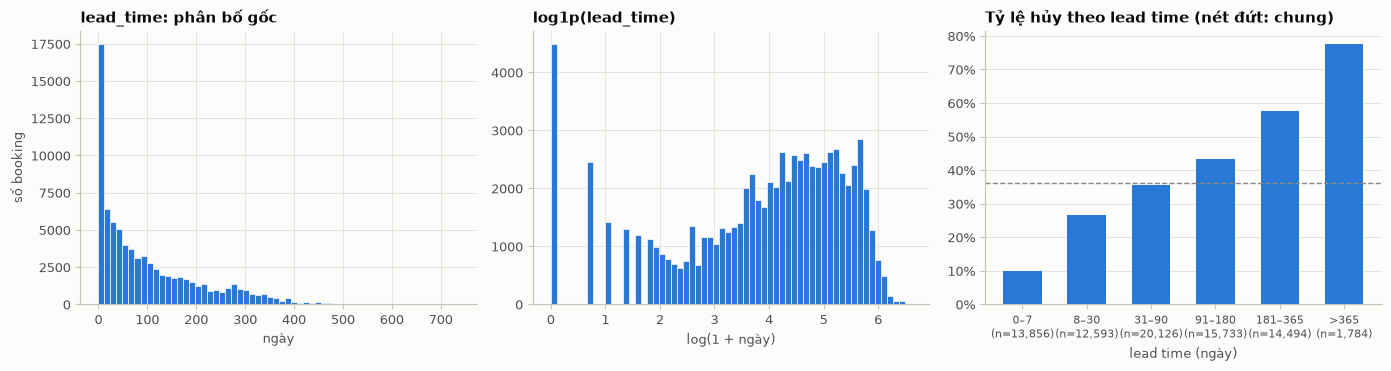

,ty_le_huy,n
lead_time,,
0–7,0.100,13856
8–30,0.265,12593
31–90,0.356,20126
91–180,0.435,15733
181–365,0.577,14494
>365,0.776,1784


In [3]:
bins = [-1, 7, 30, 90, 180, 365, np.inf]
labels = ["0–7", "8–30", "31–90", "91–180", "181–365", ">365"]
lead_rate = y.groupby(pd.cut(train.lead_time, bins, labels=labels), observed=True).agg(ty_le_huy="mean", n="size")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].hist(train.lead_time, bins=60, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
axes[0].set(title="lead_time: phân bố gốc", xlabel="ngày", ylabel="số booking")
axes[1].hist(np.log1p(train.lead_time), bins=60, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
axes[1].set(title="log1p(lead_time)", xlabel="log(1 + ngày)")
axes[2].bar(range(len(lead_rate)), lead_rate.ty_le_huy, color=BLUE, width=0.6)
axes[2].set_xticks(range(len(lead_rate)), [f"{l}\n(n={n:,})" for l, n in zip(lead_rate.index, lead_rate.n)], fontsize=8)
axes[2].axhline(overall, color=MUTED, linestyle="--", linewidth=1)
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[2].set(title="Tỷ lệ hủy theo lead time (nét đứt: chung)", xlabel="lead time (ngày)")
axes[2].grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG / "eda_lead_time.png", dpi=150); plt.show()
lead_rate.round(3)

`lead_time` lệch phải mạnh (đuôi tới hơn 700 ngày). Tỷ lệ hủy tăng nhanh ở vùng lead time ngắn rồi chậm dần:
dạng gần với log. Các biến đếm khác (`stays_*`, `previous_*`, `adults`...) cũng lệch phải (bảng dưới).
**Quyết định (D-12):** áp dụng `log1p` + chuẩn hóa cho các biến đếm trong `Pipeline`; kiểm chứng bằng ablation
A1 trên validation.

In [4]:
counts = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
          "previous_cancellations", "previous_bookings_not_canceled"]
train[counts].agg(["mean", "median", "max", "skew"]).T.round(2)

,mean,median,max,skew
lead_time,101.38,65.0,737.0,1.28
stays_in_weekend_nights,0.90,1.0,19.0,1.31
stays_in_week_nights,2.45,2.0,50.0,2.67
adults,1.85,2.0,55.0,23.51
children,0.09,0.0,10.0,4.46
babies,0.01,0.0,10.0,26.95
previous_cancellations,0.13,0.0,26.0,20.29
previous_bookings_not_canceled,0.12,0.0,58.0,22.43


## 3. Biến phân loại: kênh, phân khúc, loại khách, mùa vụ

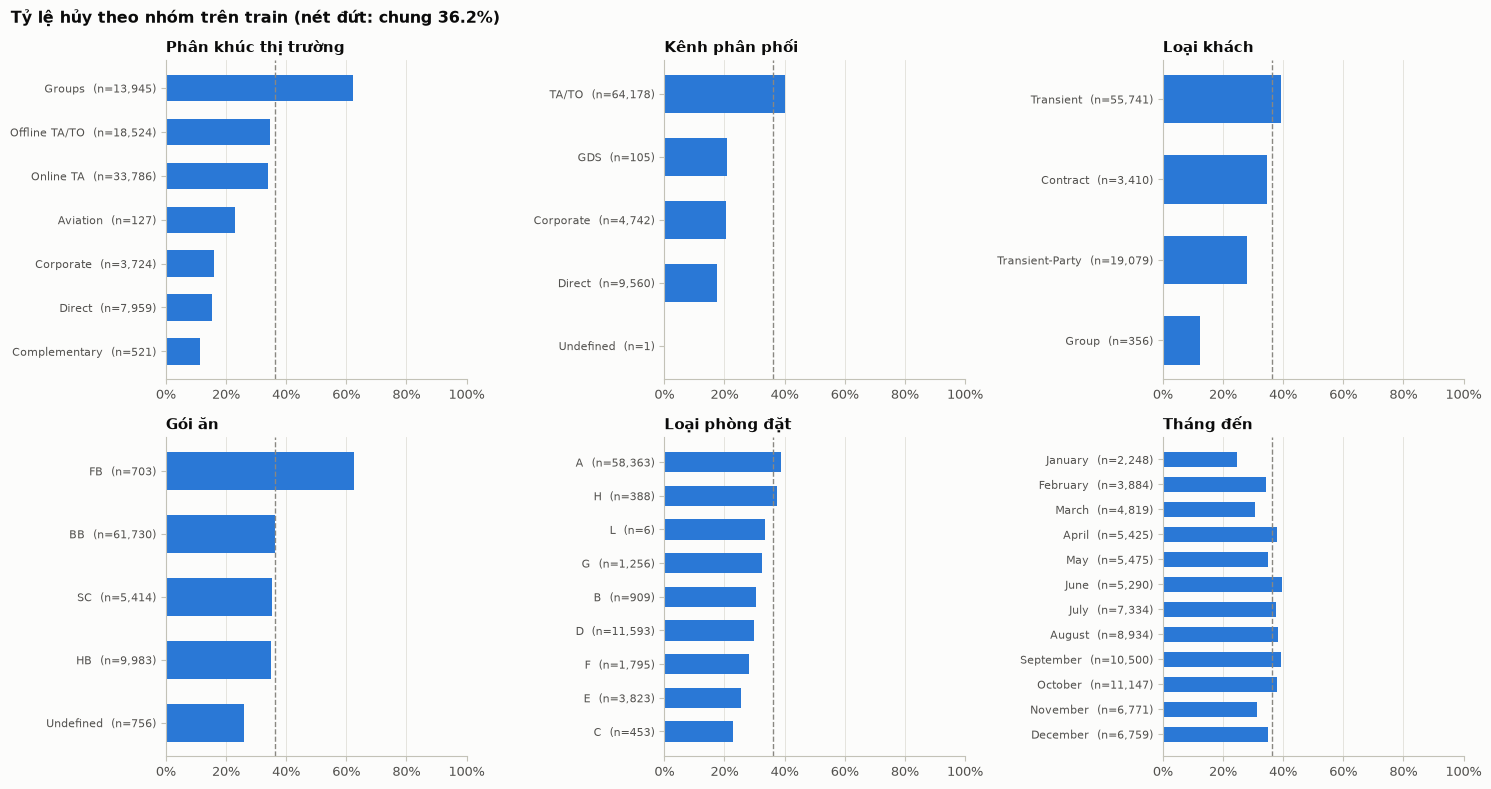

In [5]:
panels = [("market_segment", "Phân khúc thị trường"), ("distribution_channel", "Kênh phân phối"),
          ("customer_type", "Loại khách"), ("meal", "Gói ăn"), ("reserved_room_type", "Loại phòng đặt"),
          ("arrival_date_month", "Tháng đến")]
months = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October",
          "November", "December"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (col, title) in zip(axes.flat, panels):
    st = rate_by(col)
    if col == "arrival_date_month":
        st = st.reindex(months)
    pos = np.arange(len(st))
    ax.barh(pos, st.ty_le_huy, color=BLUE, height=0.6)
    ax.set_yticks(pos, [f"{i}  (n={n:,})" for i, n in zip(st.index, st.n)], fontsize=8)
    ax.invert_yaxis()
    ax.axvline(overall, color=MUTED, linestyle="--", linewidth=1)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
fig.suptitle(f"Tỷ lệ hủy theo nhóm trên train (nét đứt: chung {overall:.1%})", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "eda_categorical.png", dpi=150); plt.show()

- Phân khúc *Groups* và kênh *TA/TO* hủy nhiều; *Direct*, *Corporate*, *Complementary* hủy ít. Loại khách
  *Transient* hủy nhiều hơn *Contract*/*Group*.
- Tỷ lệ hủy dao động theo tháng đến (mùa vụ).
- Một số hạng mục rất hiếm (phòng `L`: 6 dòng; kênh `Undefined`: 1 dòng).

**Quyết định:** one-hot cho 7 biến phân loại, hạng mục < 50 dòng gộp nhóm hiếm (D-12); giữ
`arrival_date_month` nhưng **không** dùng năm/tuần/ngày (D-09).

## 4. Lịch sử của khách

In [6]:
pd.concat({
    "previous_cancellations": y.groupby(train.previous_cancellations.clip(upper=3)).agg(ty_le_huy="mean", n="size"),
    "is_repeated_guest": y.groupby(train.is_repeated_guest).agg(ty_le_huy="mean", n="size"),
}).round(3)

ty_le_huy      n
previous_cancellations 0      0.312  72384
                       1      0.970   5854
                       2      0.416     77
                       3      0.672    271
is_repeated_guest      0      0.367  76202
                       1      0.203   2384

`previous_cancellations = 1` có tỷ lệ hủy ~97% (5.854 booking), trong khi `= 2` chỉ ~42%: không đơn điệu,
dấu hiệu của các đợt booking theo đoàn bị hủy hàng loạt. Khách lặp lại hủy ít hơn khách mới (khoảng 20% so với 37%).
**Quyết định (D-08):** giữ (đề bài liệt kê "lịch sử hủy có trước" là đầu vào hợp lệ) nhưng ghi rõ rủi ro mô hình
phụ thuộc vào biến này trong model card và phân tích lỗi.

## 5. Kiểm tra rò rỉ: biến có dấu hiệu được ghi nhận sau thời điểm đặt

Một biến thật sự "biết lúc đặt" hiếm khi tách lớp tuyệt đối. Bảng và hình dưới (train) cho thấy các trường hợp
đáng ngờ.

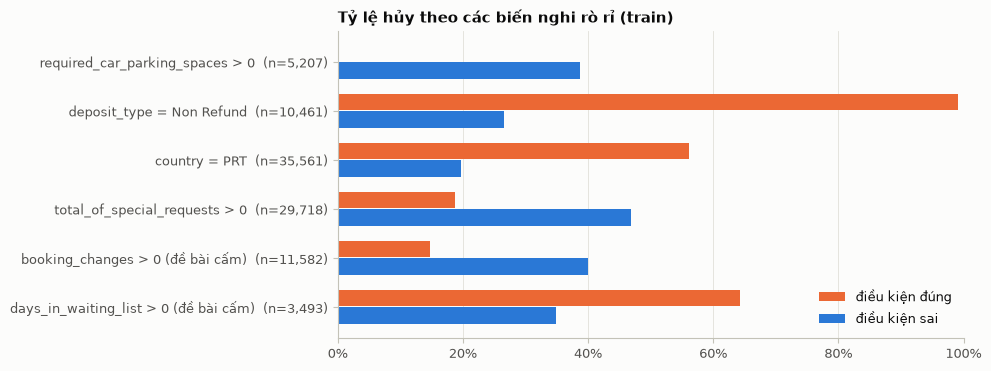

,n,hủy khi đúng,hủy khi sai
required_car_parking_spaces > 0,5207.0,0.000,0.388
deposit_type = Non Refund,10461.0,0.992,0.265
country = PRT,35561.0,0.562,0.197
total_of_special_requests > 0,29718.0,0.187,0.469
booking_changes > 0 (đề bài cấm),11582.0,0.148,0.399
days_in_waiting_list > 0 (đề bài cấm),3493.0,0.643,0.349


In [7]:
suspects = {
    "required_car_parking_spaces > 0": train.required_car_parking_spaces > 0,
    "deposit_type = Non Refund": train.deposit_type == "Non Refund",
    "country = PRT": train.country == "PRT",
    "total_of_special_requests > 0": train.total_of_special_requests > 0,
    "booking_changes > 0 (đề bài cấm)": train.booking_changes > 0,
    "days_in_waiting_list > 0 (đề bài cấm)": train.days_in_waiting_list > 0,
}
leak = pd.DataFrame({k: {"n": int(m.sum()), "hủy khi đúng": y[m].mean(), "hủy khi sai": y[~m].mean()}
                     for k, m in suspects.items()}).T
fig, ax = plt.subplots(figsize=(10, 3.8))
pos = np.arange(len(leak))
ax.barh(pos - 0.18, leak["hủy khi đúng"], height=0.34, color=ORANGE, label="điều kiện đúng")
ax.barh(pos + 0.18, leak["hủy khi sai"], height=0.34, color=BLUE, label="điều kiện sai")
ax.set_yticks(pos, [f"{k}  (n={int(n):,})" for k, n in zip(leak.index, leak.n)])
ax.invert_yaxis(); ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right"); ax.set_title("Tỷ lệ hủy theo các biến nghi rò rỉ (train)")
fig.tight_layout(); fig.savefig(FIG / "eda_leakage.png", dpi=150); plt.show()
leak.round(3)

- Có chỗ đậu xe → **0%** hủy: gần như chắc chắn ghi lúc check-in. **Loại** (D-03).
- `Non Refund` → ~99% hủy, ngược logic kinh doanh. **Không dùng trong mô hình chính** (D-05).
- PRT hủy cao hơn hẳn: nghi quốc tịch được sửa lúc check-in, cộng rủi ro phân biệt theo quốc tịch. **Loại** (D-04).
- Yêu cầu đặc biệt có thể bổ sung sau lúc đặt. **Không dùng trong mô hình chính** (D-05).
- `booking_changes`, `days_in_waiting_list`: đề bài bắt buộc loại.

## 6. Dòng trùng lặp

In [8]:
from src.features import FEATURES
dup = train.duplicated(subset=FEATURES + ["arrival_date", "is_canceled"], keep=False)
grp = train[dup].groupby(FEATURES + ["arrival_date"]).size()
print(f"Dòng thuộc nhóm trùng (đặc trưng + ngày đến + nhãn): {dup.sum():,} ({dup.mean():.1%})")
print(f"Số nhóm: {len(grp):,}; nhóm lớn nhất: {grp.max()} booking")
print("Phân khúc của các dòng trùng:")
print(train.loc[dup, "market_segment"].value_counts(normalize=True).round(3).head())

Dòng thuộc nhóm trùng (đặc trưng + ngày đến + nhãn): 35,919 (45.7%)
Số nhóm: 7,131; nhóm lớn nhất: 180 booking
Phân khúc của các dòng trùng:
market_segment
Groups           0.366
Offline TA/TO    0.320
Online TA        0.221
Direct           0.046
Corporate        0.043
Name: proportion, dtype: float64


Dòng trùng tập trung ở phân khúc theo đoàn (Groups, Offline TA/TO): nhiều phòng của cùng một đoàn, cùng ngày đến.
**Quyết định (D-10, D-11):** giữ lại; chia train/validation/test theo **ngày đến** nên các bản trùng luôn nằm cùng
một tập (không rò rỉ giữa các tập), và bootstrap theo cụm ngày đến khi tính khoảng tin cậy (D-15).

## 7. Tóm tắt quyết định từ EDA

| Phát hiện (train) | Quyết định |
|---|---|
| Lead time và biến đếm lệch phải, quan hệ dạng log | `log1p` + chuẩn hóa (D-12), kiểm chứng ablation A1 |
| Hạng mục hiếm (< 50 dòng) | one-hot với nhóm hiếm (D-12) |
| Mùa vụ theo tháng; năm không ngoại suy được | giữ tháng, bỏ năm/tuần/ngày (D-09) |
| Chỗ đậu xe, Non Refund, PRT tách lớp bất thường | loại hoặc chỉ dùng cho ablation (D-03, D-04, D-05) |
| `previous_cancellations = 1` hủy 97% | giữ, nêu rủi ro (D-08) |
| 1/3 dòng trùng theo đoàn | giữ, chia theo ngày đến, bootstrap theo cụm (D-10, D-11, D-15) |